# LaSOT EDA (full-overlap protocol, part-1 classes only)
All logic lives in `src/`; configure classes and paths in `src/config.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src").exists():       # find repo root whether run from src/eda or notebooks
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from src import config as C
from src.data.lasot import load_classes, read_split
from src.eda import stats, plots
pd.set_option("display.width", 160)
C.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("data:", C.DATA_ROOT, "| classes:", C.CLASSES)

data: /Users/andriigovorov/Documents/AIcourse2026/wm-tracking/Object-Tracking/data | classes: ['person']


## 1. Load and validate

In [2]:
seqs = load_classes(C.DATA_ROOT, C.CLASSES)
print(len(seqs), "sequences")
for s in seqs:
    if s.issues:
        print(s.name, "->", s.issues)

20 sequences
person-3 -> ['1 absent frames with non-empty box']
person-4 -> ['9 absent frames with non-empty box']
person-7 -> ["1 'present' frames with empty box", '12 absent frames with non-empty box']
person-8 -> ['16 absent frames with non-empty box']
person-11 -> ['13 absent frames with non-empty box']
person-17 -> ['15 absent frames with non-empty box']
person-18 -> ['20 absent frames with non-empty box']


In [3]:
seqs_df = stats.sequence_table(seqs)
frames = stats.frame_table(seqs)
seqs_df.drop(columns="nlp").head()

,cls,seq,n_frames,duration_s,width,height,n_foc,n_oov,n_both,frac_foc,frac_oov,frac_absent,n_foc_episodes,n_oov_episodes,max_foc_len,max_oov_len,first_absence_pos,has_issues,resolution
0,person,person-1,5550,185.000000,1280,720,11,0,0,0.001982,0.0,0.001982,4,0,4,0,0.297838,False,1280x720
1,person,person-2,5050,168.333333,1280,720,0,0,0,0.000000,0.0,0.000000,0,0,0,0,NaN,False,1280x720
2,person,person-3,3501,116.700000,1280,720,1,0,0,0.000286,0.0,0.000286,1,0,1,0,0.904027,True,1280x720
3,person,person-4,2465,82.166667,540,360,9,0,0,0.003651,0.0,0.003651,3,0,7,0,0.506694,True,540x360
4,person,person-5,2967,98.900000,1280,720,2,0,0,0.000674,0.0,0.000674,1,0,2,0,0.731378,False,1280x720


## 2. Target size and aspect ratio (present frames only)

cls                   person
rel_area count  63916.000000
         mean       0.074100
         std        0.073637
         min        0.000516
         25%        0.016900
         50%        0.039568
         75%        0.113178
         max        0.564800
aspect   count  63916.000000
         mean       0.480042
         std        0.212219
         min        0.072072
         25%        0.342193
         50%        0.415808
         75%        0.558370
         max        3.313725

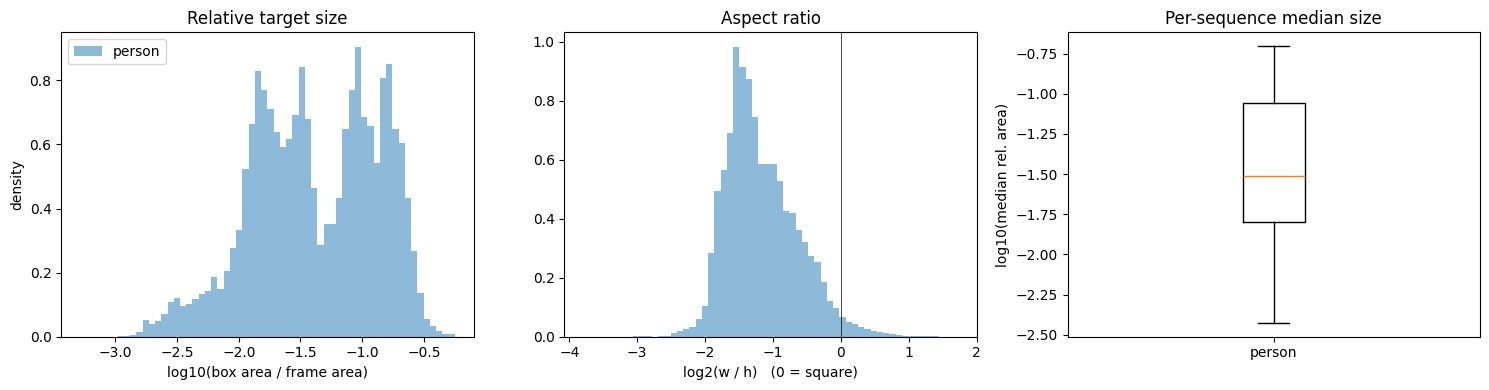

In [4]:
plots.plot_size_aspect(frames, save="size_aspect.png")
frames.groupby("cls")[["rel_area", "aspect"]].describe().T

## 3. Absent frames: full occlusion vs out-of-view

,frac_foc,frac_oov,frac_absent,n_foc_episodes,n_oov_episodes
cls,,,,,
person,0.002827,0.002372,0.005199,1.5,0.05


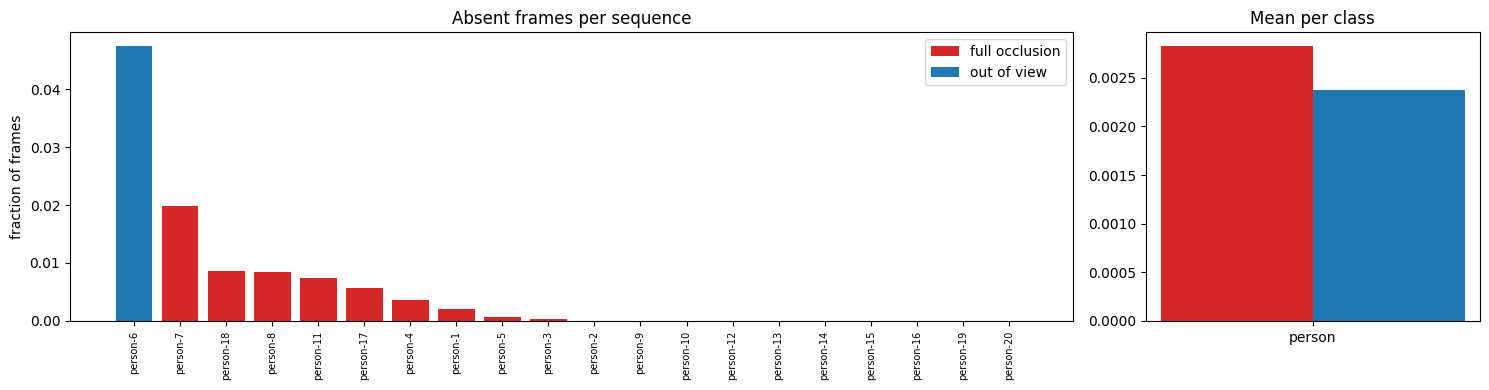

In [5]:
plots.plot_absence(seqs_df, save="absence.png")
seqs_df.groupby("cls")[["frac_foc", "frac_oov", "frac_absent", "n_foc_episodes", "n_oov_episodes"]].mean()

In [6]:
print("videos with FOC:", (seqs_df.n_foc > 0).sum(), "| with OOV:", (seqs_df.n_oov > 0).sum(), "| both flags on same frame:", (seqs_df.n_both > 0).sum())

videos with FOC: 9 | with OOV: 1 | both flags on same frame: 0


## 4. Video length and resolution

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
person,20.0,3205.5,1570.048859,1054.0,2071.75,2775.0,4028.5,6469.0


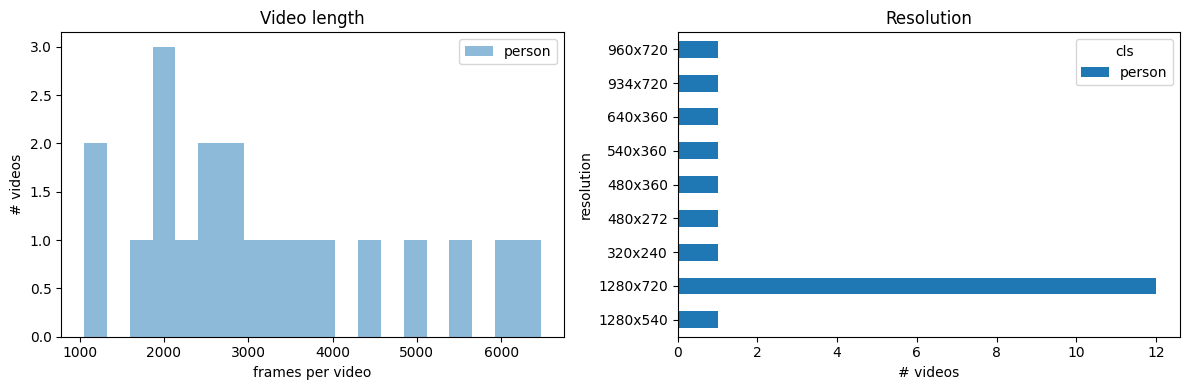

In [7]:
plots.plot_length_resolution(seqs_df, save="length_resolution.png")
seqs_df.groupby("cls").n_frames.describe()

## 5. Attributes
Official labels (`annos/*.txt`) are used once `C.ATTRIBUTE_ORDER` is set

,prevalence,SV,ARC,LR,FM,FOC,OV
0,0.35,0.35,0.25,0.50,0.45,0.60,0.60
1,0.75,0.75,0.75,0.50,0.55,0.70,0.30
2,0.85,0.85,0.95,0.40,0.45,0.50,0.20
3,0.60,0.60,0.60,0.45,0.30,0.45,0.45
4,0.45,0.45,0.45,0.50,0.65,0.70,0.50
5,0.35,0.35,0.45,0.30,0.45,0.30,0.60
6,0.80,0.80,0.80,0.35,0.30,0.45,0.25
7,0.05,0.05,0.15,0.60,0.65,0.50,0.90
8,1.00,1.00,0.90,0.35,0.30,0.45,0.05
9,0.45,0.45,0.45,0.60,0.75,1.00,0.50


,SV,ARC,LR,FM,FOC,OV
cls,,,,,,
person,20,18,7,6,9,1


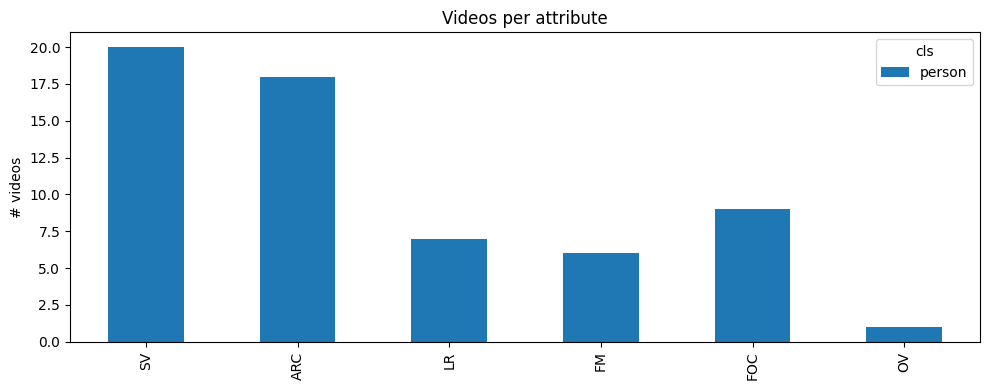

In [8]:
from src.data.lasot import load_attribute_matrix
derived = stats.derived_attributes(frames, seqs_df)
official = None
if C.ATTRIBUTE_DIR.exists():
    raw = load_attribute_matrix(C.ATTRIBUTE_DIR, seqs_df.seq)
    display(stats.check_attribute_columns(raw, derived))          # which file column is FOC / OV / ...?
    if C.ATTRIBUTE_ORDER:                                         # set in config.py after verifying
        official = stats.name_attribute_columns(raw, C.ATTRIBUTE_ORDER)
else:
    print("No official attributes at", C.ATTRIBUTE_DIR, "- using derived proxies only")
attr = stats.merge_official_attributes(derived, official)
counts = stats.attribute_counts(attr)
plots.plot_attribute_counts(counts, save="attribute_counts.png")
counts

## 6. Temporal density of occlusions / out-of-view

count       mean       std   min   25%   50%    75%   max
cls    kind                                                               
person full_occ   30.0   4.766667  3.918861   1.0   2.0   4.0   6.75  15.0
       out_view    1.0  50.000000       NaN  50.0  50.0  50.0  50.00  50.0

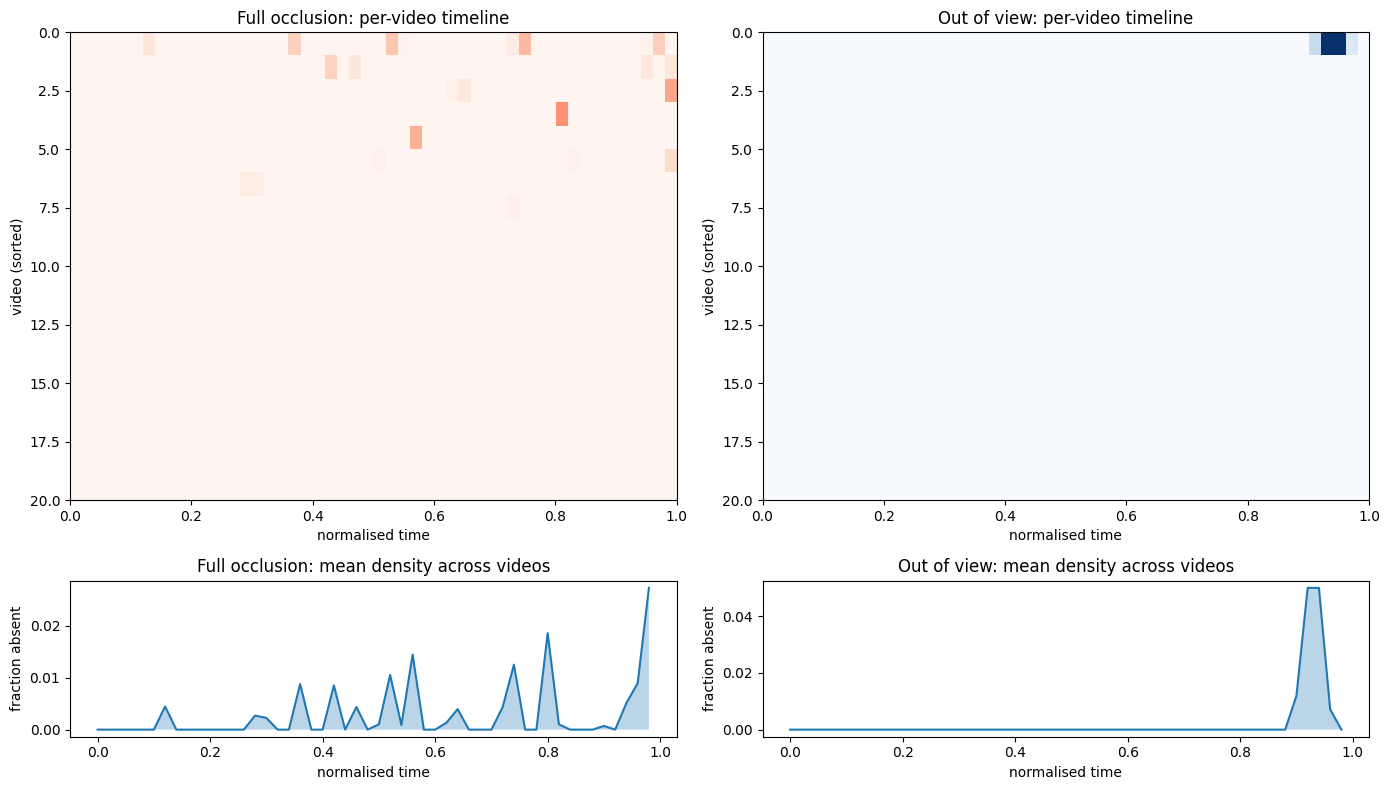

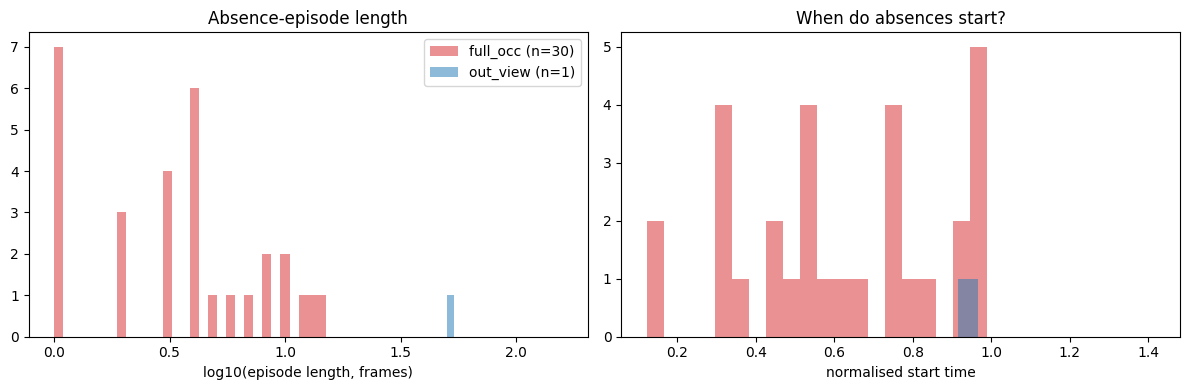

In [9]:
dens_foc = stats.temporal_density(seqs, "full_occ")
dens_oov = stats.temporal_density(seqs, "out_view")
episodes = stats.episodes_table(seqs)
plots.plot_temporal_density(dens_foc, dens_oov, save="temporal_density.png")
plots.plot_episodes(episodes, save="episodes.png")
episodes.groupby(["cls", "kind"]).length.describe()

## 7. Do the test videos cover a spread of attributes?

blind spots (class, attribute): [('person', 'OV')]


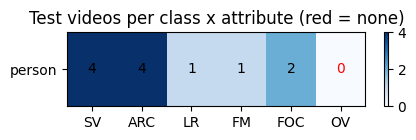

In [10]:
test = read_split(C.SPLIT_FILE)
if test is None:
    print("No split file at", C.SPLIT_FILE, "- download the official test list first.")
else:
    cov = stats.coverage_table(attr, test)
    plots.plot_coverage(cov, save="test_coverage.png")
    print("blind spots (class, attribute):", [(c, a) for c in cov.index for a in cov.columns if cov.loc[c, a] == 0])
    cov

## 8. Visual sanity check of annotations

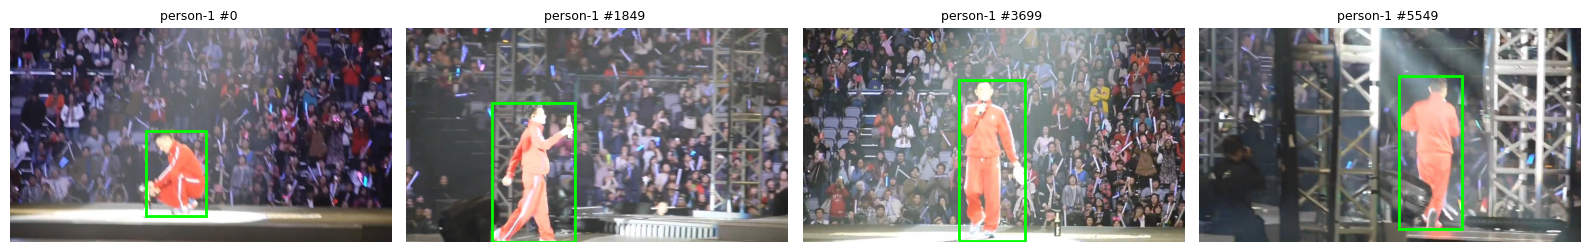

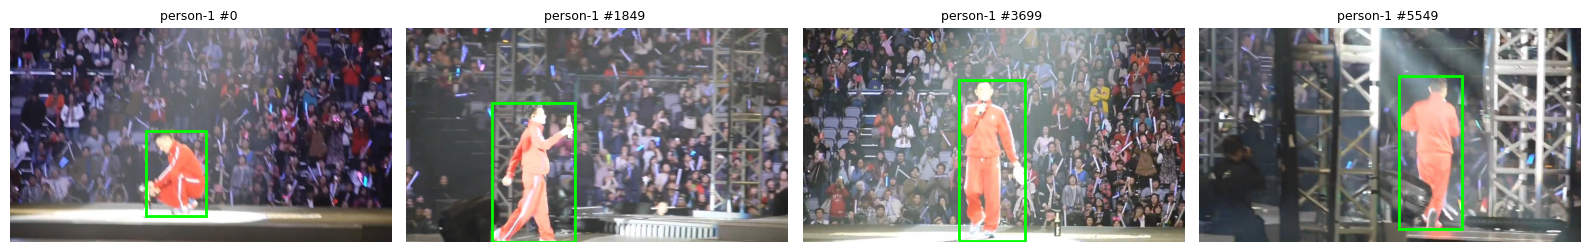

In [11]:
plots.show_samples(seqs[0], n=4)

## 9. Save tables (small CSVs can be committed)

In [12]:
seqs_df.to_csv(C.RESULTS_DIR / "sequences.csv", index=False)
counts.to_csv(C.RESULTS_DIR / "attribute_counts.csv")
episodes.to_csv(C.RESULTS_DIR / "episodes.csv", index=False)
attr.to_csv(C.RESULTS_DIR / "attributes_per_sequence.csv")